# Homework 4: Evaluation Metrics for Classification

[Homework instructions](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/04-evaluation/homework.md) · [Module materials](https://github.com/DataTalksClub/machine-learning-zoomcamp/tree/main/cohorts/2026/04-evaluation)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ivazin/ml-zoomcamp/blob/main/hw-04/homework_04.ipynb)

Run all cells to explore the six questions. This notebook downloads its data and contains all the required functions; it does not import local project files. Tables and plots stay in the notebook, with no JSON or CSV result exports.

## Runtime setup

In Colab, choose **Runtime → Run all**. Locally, use the homework's Python environment. The first run needs internet access. Missing packages are installed automatically.

In [1]:
import importlib.util
import subprocess
import sys

requirements = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])


In [2]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from sklearn.model_selection import KFold, train_test_split

DATA_URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
DATA_SHA256 = "2d9da196bdefd2a45aa0a17ca21c19f06a5d9d56af628be1f04bbb3531cc12e9"
NUMERICAL = ["lead_score", "number_of_courses_viewed", "interaction_count", "annual_income"]
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)


Python: 3.14.7
NumPy: 2.5.4 pandas: 3.0.6 scikit-learn: 1.9.1


## Prepare and split the data

We are predicting `converted`. Empty categorical values become `NA`; empty numerical values become `0.0`. These fixed replacements do not learn statistics from held-out rows.

Use the assignment's split seed, **1**, rather than the seed from HW-03. Keep the test set aside throughout the experiments. The target stays in the split tables for convenience, but is removed before encoding.

In [3]:
def load_data(path):
    """Download the pinned release if missing, then fill missing values."""
    path = Path(path)
    if not path.exists():
        with urlopen(DATA_URL, timeout=60) as response:
            content = response.read()
        if hashlib.sha256(content).hexdigest() != DATA_SHA256:
            raise ValueError("Downloaded dataset does not match the pinned release.")
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(content)
    if hashlib.sha256(path.read_bytes()).hexdigest() != DATA_SHA256:
        raise ValueError("Local dataset does not match the pinned release.")
    raw = pd.read_csv(path, keep_default_na=False, na_values=[""])
    df = raw.copy()
    categorical = df.select_dtypes(include=["object", "str"]).columns.tolist()
    df[categorical] = df[categorical].fillna("NA")
    df[NUMERICAL] = df[NUMERICAL].fillna(0.0)
    return raw, df

def split_data(df):
    full_train, test = train_test_split(df, test_size=0.2, random_state=1)
    train, val = train_test_split(full_train, test_size=0.25, random_state=1)
    return full_train, train, val, test

raw, df = load_data(Path("data/course_lead_scoring_2026.csv"))
full_train, train, val, test = split_data(df)
display(raw.isna().sum().rename("missing_before").to_frame())
print("Train / validation / test:", len(train), len(val), len(test))
assert not df.isna().any().any()
assert set(df.converted.unique()) == {0, 1}
assert set(train.index).isdisjoint(val.index)
assert set(full_train.index).isdisjoint(test.index)
df.head()

,missing_before
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


Train / validation / test: 3000 1000 1000


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Q1. A numerical feature as a ranking score

AUC measures how well a score ranks positive examples above negative ones. It does not require a classification threshold. A value below 0.5 can mean the score points in the wrong direction; negating it reverses the ranking.

Compare the listed numerical features on training data. Keep both the original and adjusted scores so the direction change is visible.

In [4]:
def feature_auc(train):
    rows = []
    for feature in NUMERICAL:
        score = train[feature].to_numpy()
        raw_auc = roc_auc_score(train.converted, score)
        inverted = raw_auc < 0.5
        adjusted_auc = roc_auc_score(train.converted, -score if inverted else score)
        rows.append({"feature": feature, "raw_auc": raw_auc,
                     "inverted": inverted, "auc": adjusted_auc})
    return pd.DataFrame(rows).set_index("feature")

feature_scores = feature_auc(train)
display(feature_scores.sort_values("auc", ascending=False))
print("Q1:", feature_scores.auc.idxmax())

,raw_auc,inverted,auc
feature,,,
lead_score,0.788225,False,0.788225
interaction_count,0.764920,False,0.764920
number_of_courses_viewed,0.722989,False,0.722989
annual_income,0.608198,False,0.608198


Q1: lead_score


## Q2. Validation AUC of logistic regression

Fit a new encoder on training rows and transform validation rows with that encoder. All features keep their original scale, following the assignment. Use probabilities for AUC: turning them into binary predictions would discard most of the ranking information.

In [5]:
def predict_probabilities(train, val, C=1.0):
    """Fit a fresh encoder and model; keep converted out of the features."""
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train.drop(columns="converted").to_dict(orient="records"))
    X_val = dv.transform(val.drop(columns="converted").to_dict(orient="records"))
    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X_train, train.converted.to_numpy())
    return model.predict_proba(X_val)[:, 1]

probabilities = predict_probabilities(train, val)
validation_auc = float(roc_auc_score(val.converted, probabilities))
print("Validation AUC:", validation_auc)
print("Q2, rounded:", round(validation_auc, 3))

Validation AUC: 0.7318222288173319
Q2, rounded: 0.732


## Q3. Precision and recall across thresholds

Precision asks how many predicted positives are correct: `TP / (TP + FP)`. Recall asks how many actual positives we recover: `TP / (TP + FN)`.

A higher threshold usually reduces the number of positive predictions. The plot helps see the trade-off, but select the intersection from the numerical table rather than estimating it by eye. When no positives are predicted, use precision 0. Exclude points where both precision and recall are zero before comparing their absolute difference.

In [6]:
def threshold_metrics(y_true, probabilities):
    """Compute confusion counts and metrics on the requested threshold grid."""
    y_true = np.asarray(y_true)
    rows = []
    for threshold in np.arange(101) / 100:
        predicted = probabilities >= threshold
        actual = y_true == 1
        tp = int((predicted & actual).sum())
        fp = int((predicted & ~actual).sum())
        fn = int((~predicted & actual).sum())
        tn = int((~predicted & ~actual).sum())
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        rows.append({"threshold": float(threshold), "tp": tp, "fp": fp,
                     "fn": fn, "tn": tn, "precision": precision,
                     "recall": recall, "f1": f1, "gap": abs(precision - recall)})
    return pd.DataFrame(rows)

def select_thresholds(metrics):
    # Ignore the trivial precision=recall=0 intersection.
    eligible = metrics.loc[(metrics.precision != 0) | (metrics.recall != 0)]
    intersection = eligible.sort_values(["gap", "threshold"]).iloc[0]
    best_f1 = metrics.sort_values(["f1", "threshold"], ascending=[False, True]).iloc[0]
    return float(intersection.threshold), float(best_f1.threshold)

metrics = threshold_metrics(val.converted.to_numpy(), probabilities)
intersection_threshold, best_f1_threshold = select_thresholds(metrics)
# Check our count-based formulas against scikit-learn at every threshold.
for row in metrics.itertuples():
    predicted = probabilities >= row.threshold
    assert np.isclose(row.precision, precision_score(val.converted, predicted, zero_division=0))
    assert np.isclose(row.recall, recall_score(val.converted, predicted, zero_division=0))
    assert np.isclose(row.f1, f1_score(val.converted, predicted, zero_division=0))
assert (metrics[["tp", "fp", "fn", "tn"]].sum(axis=1) == len(val)).all()
eligible = metrics.loc[(metrics.precision != 0) | (metrics.recall != 0)]
display(eligible.sort_values(["gap", "threshold"]).head(10))
print("Q3:", intersection_threshold)

,threshold,tp,fp,fn,tn,precision,recall,f1,gap
63,0.63,425,155,161,259,0.732759,0.725256,0.728988,0.007503
62,0.62,437,165,149,249,0.725914,0.745734,0.735690,0.019820
64,0.64,408,151,178,263,0.729875,0.696246,0.712664,0.033629
61,0.61,453,177,133,237,0.719048,0.773038,0.745066,0.053990
65,0.65,392,137,194,277,0.741021,0.668942,0.703139,0.072079
60,0.60,457,190,129,224,0.706337,0.779863,0.741281,0.073527
59,0.59,464,203,122,211,0.695652,0.791809,0.740623,0.096157
66,0.66,377,127,209,287,0.748016,0.643345,0.691743,0.104671
58,0.58,471,212,115,202,0.689605,0.803754,0.742317,0.114150
57,0.57,478,226,108,188,0.678977,0.815700,0.741085,0.136722


Q3: 0.63


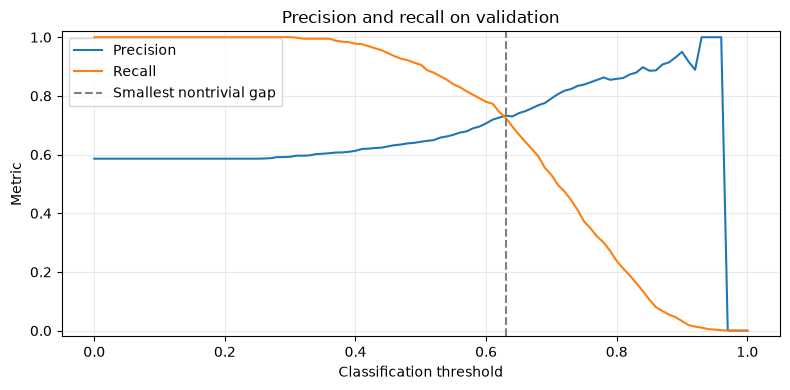

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(metrics.threshold, metrics.precision, label="Precision")
ax.plot(metrics.threshold, metrics.recall, label="Recall")
ax.axvline(intersection_threshold, color="grey", linestyle="--", label="Smallest nontrivial gap")
ax.set(xlabel="Classification threshold", ylabel="Metric", title="Precision and recall on validation", ylim=(-0.02, 1.02))
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Q4. Find the maximum F1

F1 is the harmonic mean of precision and recall: `2 * P * R / (P + R)`. It is low when either component is low. Use the same threshold grid and the same validation probabilities; changing the model here would make the comparison harder to interpret.

Show the best candidates before choosing a threshold. If several grid points tie exactly, this workflow selects the smallest threshold and shows all tied points.

,threshold,tp,fp,fn,tn,precision,recall,f1,gap
41,0.41,572,352,14,62,0.619048,0.976109,0.757616,0.357062
42,0.42,568,348,18,66,0.620087,0.969283,0.756325,0.349196
43,0.43,564,342,22,72,0.622517,0.962457,0.756032,0.339941
45,0.45,554,328,32,86,0.628118,0.945392,0.754768,0.317275
44,0.44,560,338,26,76,0.623608,0.955631,0.754717,0.332023
46,0.46,548,319,38,95,0.632065,0.935154,0.754301,0.303089
48,0.48,540,306,46,108,0.638298,0.921502,0.754190,0.283204
40,0.40,573,362,13,52,0.612834,0.977816,0.753452,0.364981
47,0.47,543,313,43,101,0.634346,0.926621,0.753121,0.292275
50,0.50,531,294,55,120,0.643636,0.906143,0.752658,0.262507


,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616


Q4: 0.41


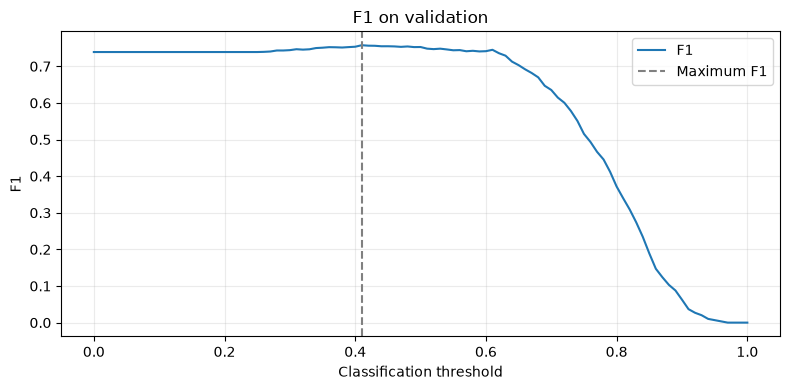

In [8]:
display(metrics.sort_values(["f1", "threshold"], ascending=[False, True]).head(10))
display(metrics.loc[metrics.f1 == metrics.f1.max(), ["threshold", "precision", "recall", "f1"]])
print("Q4:", best_f1_threshold)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(metrics.threshold, metrics.f1, label="F1")
ax.axvline(best_f1_threshold, color="grey", linestyle="--", label="Maximum F1")
ax.set(xlabel="Classification threshold", ylabel="F1", title="F1 on validation")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Q5. Variation across folds

Cross-validation rotates the held-out rows, so we can see whether performance depends heavily on a single split. Use the full training partition and the prescribed shuffled `KFold`, with no test rows.

The encoder must be fitted again inside each fold. Calculate the population standard deviation (`ddof=0`), as with NumPy's default `std`. Inspect individual fold scores as well as their summary.

In [9]:
def cross_validate(full_train, C):
    splitter = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in splitter.split(full_train):
        train, val = full_train.iloc[train_idx], full_train.iloc[val_idx]
        probabilities = predict_probabilities(train, val, C=C)
        scores.append(float(roc_auc_score(val.converted, probabilities)))
    return np.asarray(scores)

fold_scores = cross_validate(full_train, C=1.0)
display(pd.DataFrame({"fold": np.arange(1, 6), "auc": fold_scores}))
print("Mean AUC:", float(fold_scores.mean()))
print("Standard deviation:", float(fold_scores.std(ddof=0)))
print("Q5, rounded:", round(float(fold_scores.std(ddof=0)), 3))

,fold,auc
0,1,0.730560
1,2,0.729573
2,3,0.736343
3,4,0.741245
4,5,0.720914


Mean AUC: 0.7317269710972524
Standard deviation: 0.006853233151022138
Q5, rounded: 0.007


## Q6. Compare regularization strengths

Reuse the same folds for each `C`, so differences come from the model setting rather than different validation rows. Compare the rounded mean first, then the rounded standard deviation, then `C` itself.

A smaller `C` applies stronger regularization. A high mean is useful, but the spread across folds tells us how consistently that performance appears.

In [10]:
def tune_regularization(full_train):
    rows = []
    for C in [0.000001, 0.001, 1.0]:
        scores = cross_validate(full_train, C)
        mean, std = float(scores.mean()), float(scores.std(ddof=0))
        rows.append({"C": C, "fold_scores": scores.tolist(), "mean_auc": mean,
                     "std_auc": std, "mean_rounded": round(mean, 3),
                     "std_rounded": round(std, 3)})
    return pd.DataFrame(rows)

# Evaluate each setting with the same folds, including the Q5 baseline.
tuning = tune_regularization(full_train)
# The deterministic fold split must match Q5; allow minor solver variation.
assert np.allclose(tuning.loc[tuning.C == 1.0, "fold_scores"].iloc[0], fold_scores, atol=1e-6)
ranked = tuning.sort_values(["mean_rounded", "std_rounded", "C"], ascending=[False, True, True])
display(ranked)
best_C = float(ranked.iloc[0].C)
print("Q6:", best_C)

,C,fold_scores,mean_auc,std_auc,mean_rounded,std_rounded
1,0.001000,"[0.7504349221633766, 0.7475333388395098, 0.758...",0.749172,0.009996,0.749,0.010
2,1.000000,"[0.7305601027122453, 0.7295726148196622, 0.736...",0.731727,0.006853,0.732,0.007
0,0.000001,"[0.5941004654148612, 0.6402137243565715, 0.600...",0.616734,0.018670,0.617,0.019


Q6: 0.001


## Review the computed choices

The table below is calculated from the experiments above. Compare it with the homework options. If a numeric value does not match, check the data release, split seed, preprocessing, and metric definition before choosing a nearby value.

In [11]:
computed_choices = pd.Series({
    "Q1": feature_scores.auc.idxmax(),
    "Q2": round(validation_auc, 3),
    "Q3": intersection_threshold,
    "Q4": best_f1_threshold,
    "Q5": round(float(fold_scores.std(ddof=0)), 3),
    "Q6": best_C,
}, name="computed_choice")
display(computed_choices.to_frame())

,computed_choice
Q1,lead_score
Q2,0.732
Q3,0.63
Q4,0.41
Q5,0.007
Q6,0.001
